# Сравнение независимых экспериментов LFPG, EGLL и EDDF

Каждая модель обучена отдельно для своего аэропорта. Зафиксированы исходные сезонные дни 1.1: девять train, три validation и три test. Горизонт 27–33 секунды, поправка к физическому baseline, равный вклад заходов. Перенос обученной модели между аэропортами здесь не исследуется

,model,macro_mae_ft,macro_rmse_ft,run_id,airport
0,Constant vertical rate,49.348959,67.995818,af81171321ba41da902589bff85a3858,LFPG
1,Ridge,20.033286,25.796078,58f9e5e9015e4478b4c9631b4aa613d0,LFPG
2,Polynomial Ridge,17.163963,22.244615,54224c6909c1451aa7c24c45feaa2dc5,LFPG
3,PyTorch MLP,18.862559,24.466738,e1e47564e32845768281b8f447e7e21b,LFPG
4,Constant vertical rate,55.953272,81.923198,77511f5022e34b5caf1c988466047793,EGLL
5,Ridge,16.337442,24.521356,019df70260ad45ec9299b2efc60829cc,EGLL
6,Polynomial Ridge,15.448957,24.743112,a1836409248444b0ae6250bd2a1aa52c,EGLL
7,PyTorch MLP,14.516123,20.314007,7432f453bb1e46e0924dc4ae5bfb212a,EGLL
8,Constant vertical rate,72.603506,117.367842,ab3f157c9a354866bb3673c2dd4f4138,EDDF
9,Ridge,22.225478,32.310559,586f82fc484d45c69e23761575b0b58b,EDDF


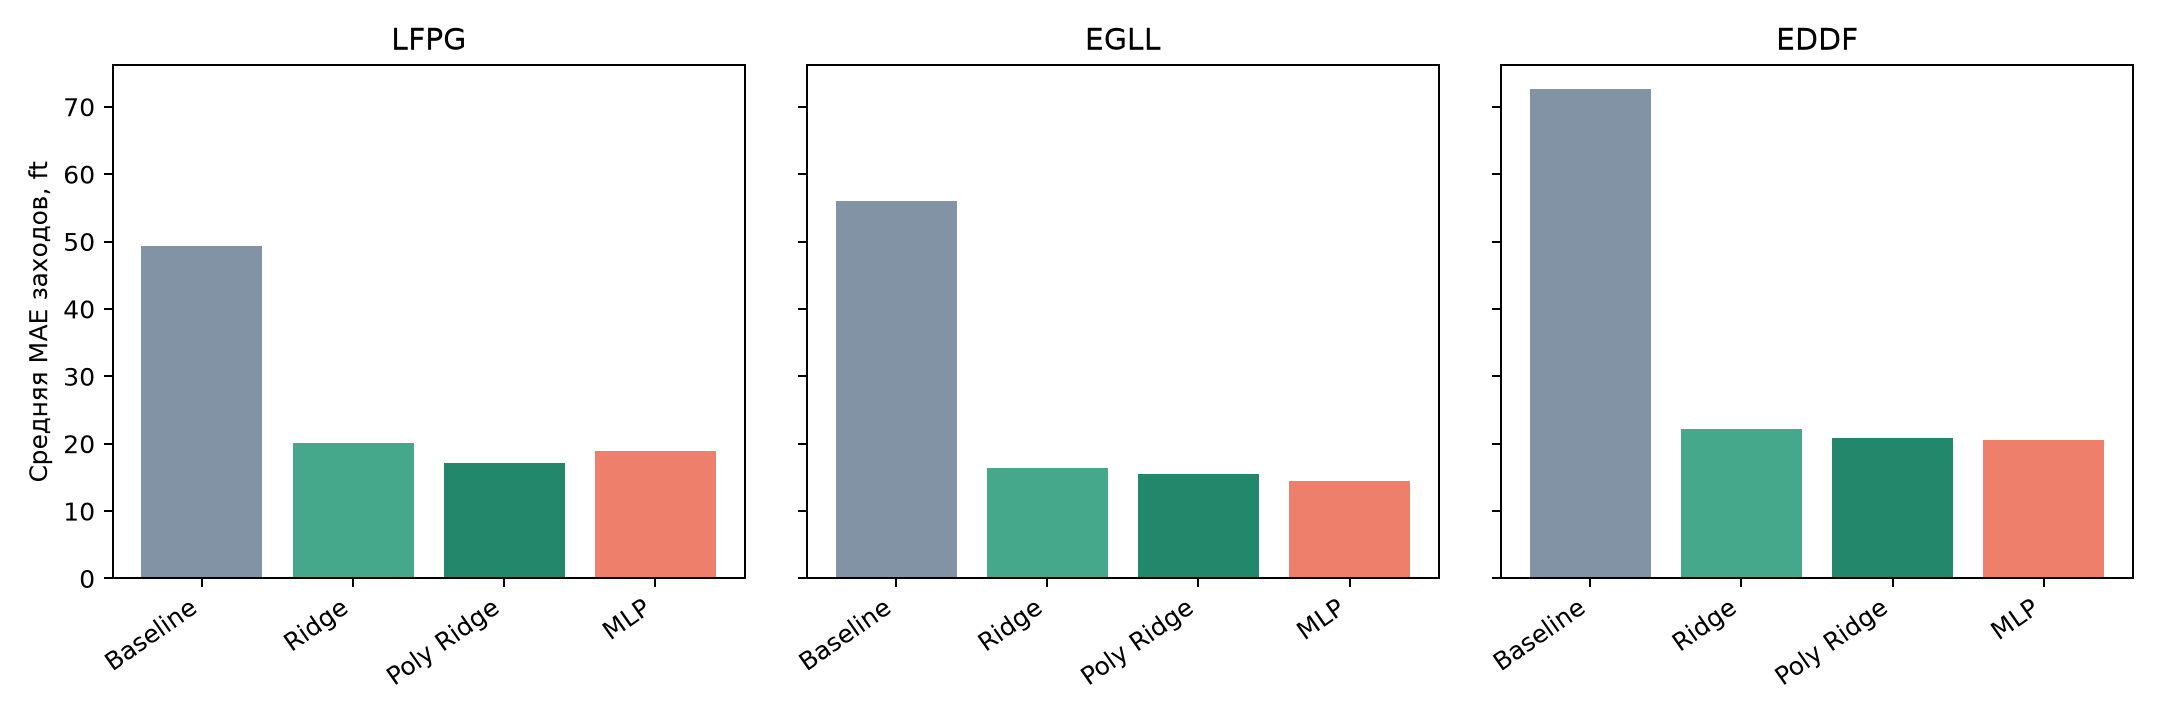

In [1]:
# Загружаем сохраненные результаты без повторного обучения
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / "reports/three_airports_metrics.csv"))
display(Image(filename=str(root / "reports/three_airports_comparison.png")))

## EGLL: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,13472,367
1,autumn,train,39770,1146
2,autumn,validation,12151,362
3,spring,test,7014,385
4,spring,train,19537,1136
5,spring,validation,6457,388
6,summer,test,15224,384
7,summer,train,41384,1156
8,summer,validation,11499,277


{'read': 166508, 'inserted': 0, 'already_present': 166508, 'database_rows': 166508, 'extracted': 166508, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,16.183624
1,Ridge,10,16.168880
2,Ridge,100,16.244204
3,Polynomial Ridge,1,15.751428
4,Polynomial Ridge,10,15.729394
5,Polynomial Ridge,100,15.972120
6,PyTorch MLP,16,15.023992
7,PyTorch MLP,32,14.886854


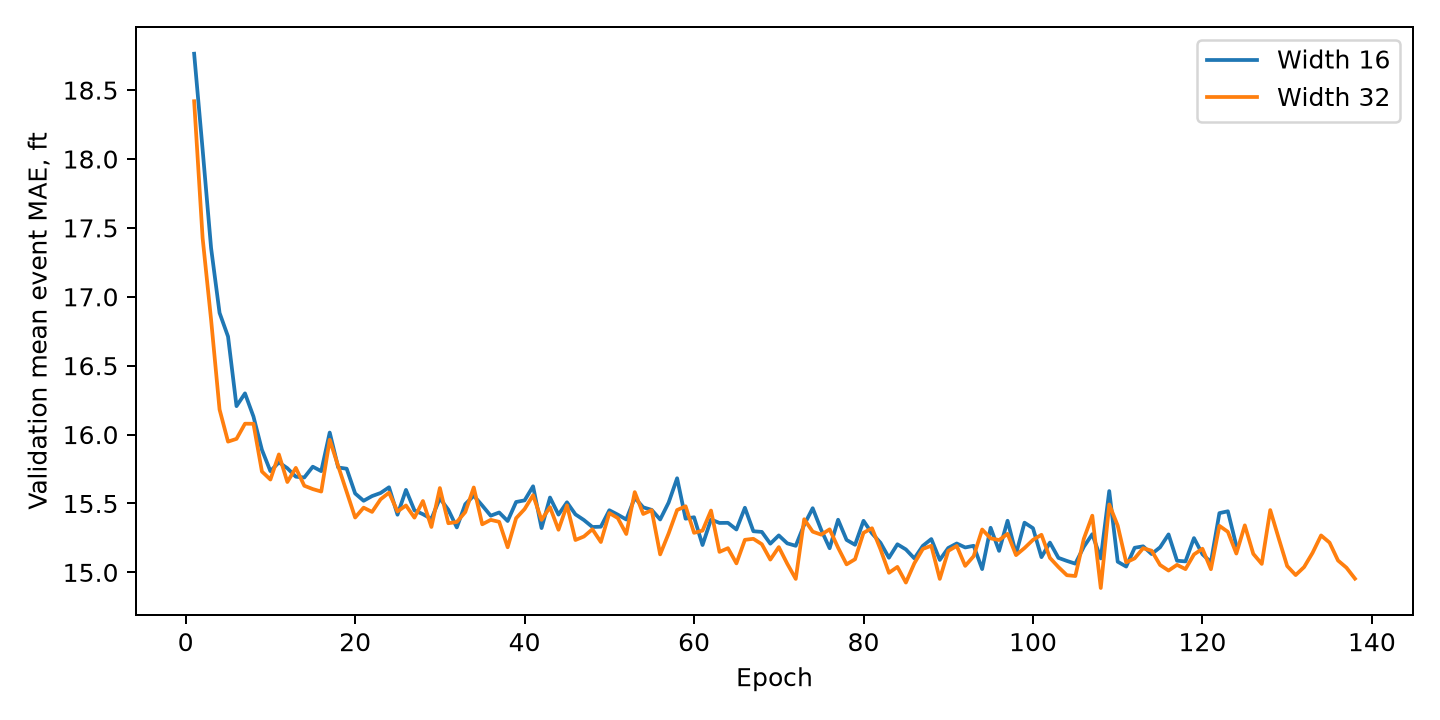

In [2]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EGLL/split_inventory.csv"))
print(json.loads((root / "reports/EGLL/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EGLL/validation_search.csv"))
display(Image(filename=str(root / "reports/EGLL/mlp_validation.png")))

## EGLL: парный анализ ошибок и неопределенности

Все сравнения выполнены на сохраненных моделях без переобучения. MAE, bias и MSE сначала усредняются внутри захода. Bias = прогноз минус наблюдение; положительный знак означает завышение высоты. P90 – 90-й процентиль MAE заходов. Сезон здесь представлен одним днем и не отделен от состава этого дня

Парный bootstrap выбирает борта с возвращением, сохраняя все заходы выбранного борта вместе. 10 000 повторов, seed 20261014, границы 2.5% и 97.5%. Интервалы условны на трех наблюдаемых днях: общая зависимость внутри дня и неопределенность обучения не моделируются. Один seed MLP, без поправки на множественные сравнения; анализ выполнен после просмотра test

,model,day,season,events,macro_mae_ft,macro_bias_ft,macro_rmse_ft,p90_event_mae_ft
0,Constant vertical rate,2025-04-07,spring,385,59.702257,-13.988528,84.084056,93.694958
1,Constant vertical rate,2025-08-25,summer,384,66.056653,-18.077972,95.645796,100.246061
2,Constant vertical rate,2025-10-18,autumn,367,41.449029,-9.467566,61.526567,62.366594
3,Polynomial Ridge,2025-04-07,spring,385,16.672512,-2.452245,31.106240,24.306193
4,Polynomial Ridge,2025-08-25,summer,384,16.203853,0.853835,23.113602,23.574887
5,Polynomial Ridge,2025-10-18,autumn,367,13.375528,-2.220266,17.916762,19.743265
6,PyTorch MLP,2025-04-07,spring,385,14.968176,-3.522923,21.164497,23.662292
7,PyTorch MLP,2025-08-25,summer,384,15.771899,-0.618000,22.237188,22.151509
8,PyTorch MLP,2025-10-18,autumn,367,12.727952,-3.708510,17.030188,18.903195
9,Ridge,2025-04-07,spring,385,17.587273,-4.666921,28.673385,25.220680


,model,reference,events,aircraft,mean_delta_mae_ft,lower_95_ft,upper_95_ft,better_events,worse_events,tied_events
0,Polynomial Ridge,Constant vertical rate,1136,642,-40.504315,-42.012510,-39.050932,1134,2,0
1,PyTorch MLP,Constant vertical rate,1136,642,-41.437150,-42.929809,-39.976214,1135,1,0
2,PyTorch MLP,Polynomial Ridge,1136,642,-0.932835,-1.134231,-0.767711,777,359,0
3,Ridge,Polynomial Ridge,1136,642,0.888485,0.758023,1.025196,321,815,0


,day,model,reference,events,mean_delta_mae_ft,better_events
6,2025-04-07,PyTorch MLP,Polynomial Ridge,385,-1.704336,312
7,2025-08-25,PyTorch MLP,Polynomial Ridge,384,-0.431954,212
8,2025-10-18,PyTorch MLP,Polynomial Ridge,367,-0.647576,253


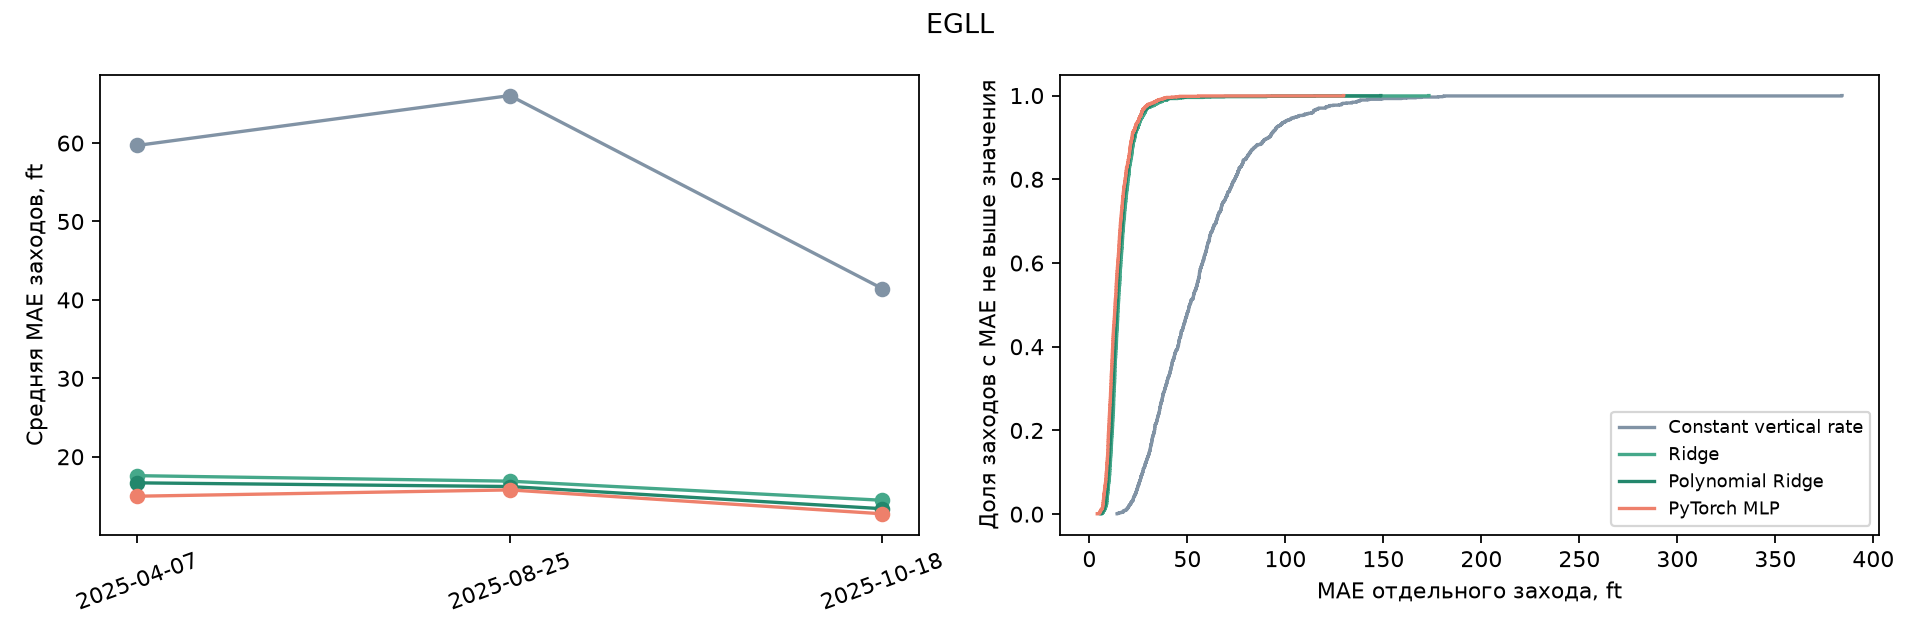

In [3]:
# Показываем ошибки по дням, парные разницы и интервалы
display(pd.read_csv(root / "reports/EGLL/errors_by_day.csv"))
display(pd.read_csv(root / "reports/EGLL/paired_uncertainty.csv"))
daily = pd.read_csv(root / "reports/EGLL/paired_errors_by_day.csv")
display(daily.loc[daily.model.eq("PyTorch MLP") & daily.reference.eq("Polynomial Ridge")])
display(Image(filename=str(root / "reports/EGLL/error_analysis.png")))

MLP улучшила Polynomial Ridge на 777 из 1136 заходов; средняя разница −0.93 ft, условный интервал −1.13…−0.77 ft. Средние разницы на всех трех днях отрицательны: −1.70, −0.43, −0.65 ft. MLP в среднем занижает высоту на каждом из этих дней. Вывод ограничен выбранной выборкой и не подтверждает перенос на другие условия

## EDDF: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,5919,172
1,autumn,train,21967,566
2,autumn,validation,6807,189
3,spring,test,6595,206
4,spring,train,9246,458
5,spring,validation,3759,177
6,summer,test,6823,162
7,summer,train,29215,533
8,summer,validation,6383,171


{'read': 96714, 'inserted': 0, 'already_present': 96714, 'database_rows': 96714, 'extracted': 96714, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,22.398563
1,Ridge,10,22.367554
2,Ridge,100,22.354038
3,Polynomial Ridge,1,21.080186
4,Polynomial Ridge,10,21.125482
5,Polynomial Ridge,100,21.635613
6,PyTorch MLP,16,20.682799
7,PyTorch MLP,32,20.528188


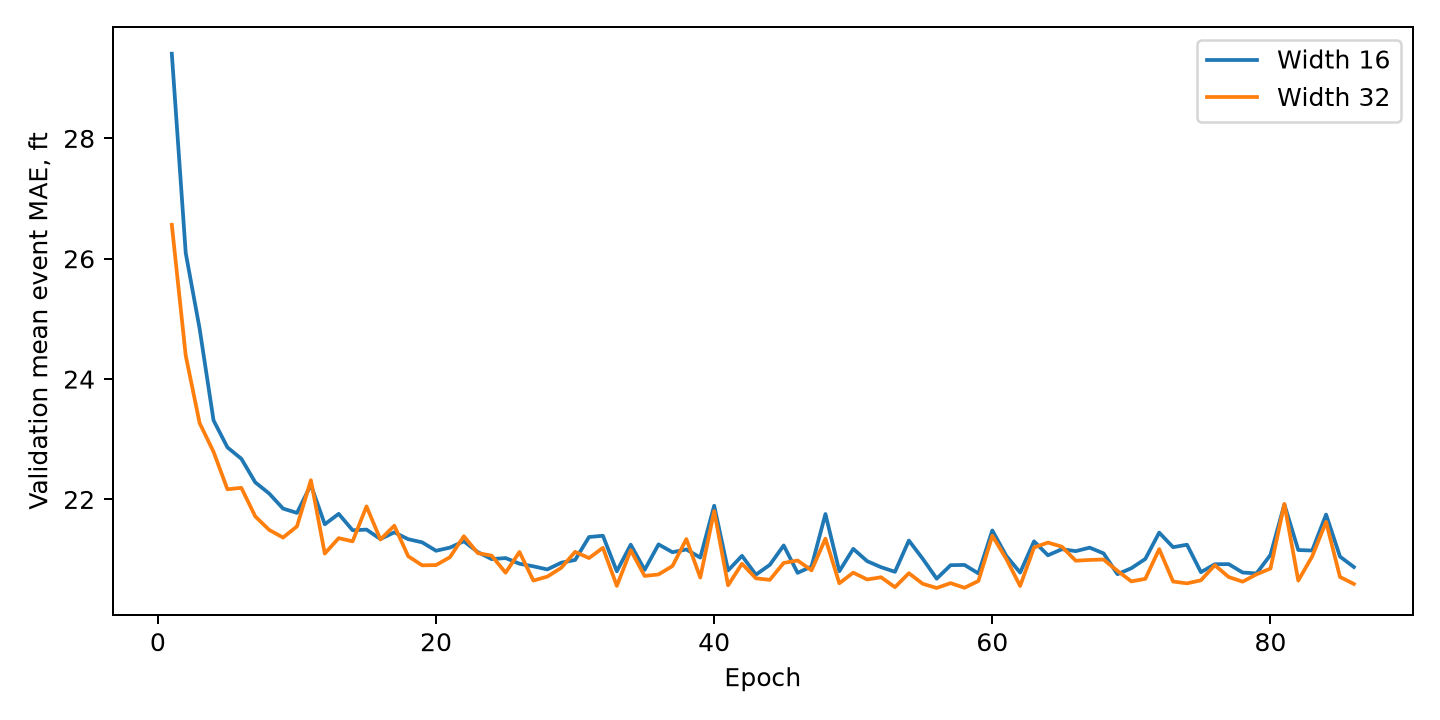

In [4]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EDDF/split_inventory.csv"))
print(json.loads((root / "reports/EDDF/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EDDF/validation_search.csv"))
display(Image(filename=str(root / "reports/EDDF/mlp_validation.png")))

## EDDF: парный анализ ошибок и неопределенности

Все сравнения выполнены на сохраненных моделях без переобучения. MAE, bias и MSE сначала усредняются внутри захода. Bias = прогноз минус наблюдение; положительный знак означает завышение высоты. P90 – 90-й процентиль MAE заходов. Сезон здесь представлен одним днем и не отделен от состава этого дня

Парный bootstrap выбирает борта с возвращением, сохраняя все заходы выбранного борта вместе. 10 000 повторов, seed 20261014, границы 2.5% и 97.5%. Интервалы условны на трех наблюдаемых днях: общая зависимость внутри дня и неопределенность обучения не моделируются. Один seed MLP, без поправки на множественные сравнения; анализ выполнен после просмотра test

,model,day,season,events,macro_mae_ft,macro_bias_ft,macro_rmse_ft,p90_event_mae_ft
0,Constant vertical rate,2025-05-09,spring,206,79.561519,-21.200500,112.238645,113.038573
1,Constant vertical rate,2025-08-18,summer,162,67.332208,-13.996006,114.538443,91.157946
2,Constant vertical rate,2025-10-19,autumn,172,69.234900,-24.028694,125.712825,116.296307
3,Polynomial Ridge,2025-05-09,spring,206,24.253531,-0.788213,34.085770,37.339892
4,Polynomial Ridge,2025-08-18,summer,162,17.809355,-0.223834,23.995827,27.415265
5,Polynomial Ridge,2025-10-19,autumn,172,19.711146,0.666544,29.232452,32.921724
6,PyTorch MLP,2025-05-09,spring,206,22.848985,1.724951,31.911291,33.081289
7,PyTorch MLP,2025-08-18,summer,162,18.166758,2.408096,24.406513,26.693684
8,PyTorch MLP,2025-10-19,autumn,172,20.080909,1.070359,29.507719,33.679368
9,Ridge,2025-05-09,spring,206,25.588231,-3.851437,36.676141,37.775396


,model,reference,events,aircraft,mean_delta_mae_ft,lower_95_ft,upper_95_ft,better_events,worse_events,tied_events
0,Polynomial Ridge,Constant vertical rate,540,302,-51.730062,-56.285218,-47.666414,540,0,0
1,PyTorch MLP,Constant vertical rate,540,302,-52.040873,-56.688870,-47.868562,540,0,0
2,PyTorch MLP,Polynomial Ridge,540,302,-0.310811,-0.563259,-0.055395,294,246,0
3,Ridge,Polynomial Ridge,540,302,1.352033,1.011691,1.739186,168,372,0


,day,model,reference,events,mean_delta_mae_ft,better_events
6,2025-05-09,PyTorch MLP,Polynomial Ridge,206,-1.404547,148
7,2025-08-18,PyTorch MLP,Polynomial Ridge,162,0.357403,78
8,2025-10-19,PyTorch MLP,Polynomial Ridge,172,0.369763,68


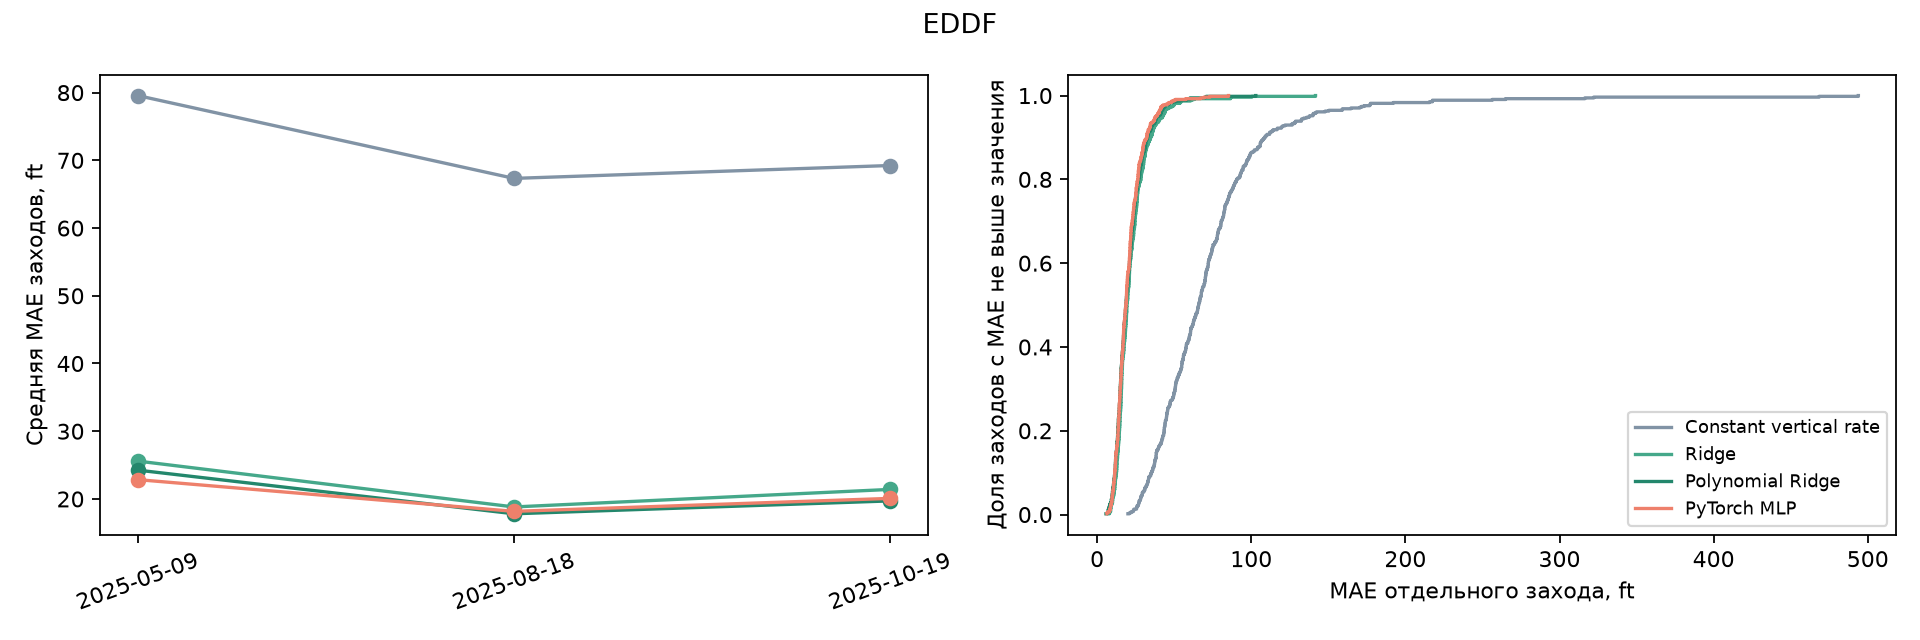

In [5]:
# Показываем ошибки по дням, парные разницы и интервалы
display(pd.read_csv(root / "reports/EDDF/errors_by_day.csv"))
display(pd.read_csv(root / "reports/EDDF/paired_uncertainty.csv"))
daily = pd.read_csv(root / "reports/EDDF/paired_errors_by_day.csv")
display(daily.loc[daily.model.eq("PyTorch MLP") & daily.reference.eq("Polynomial Ridge")])
display(Image(filename=str(root / "reports/EDDF/error_analysis.png")))

MLP улучшила Polynomial Ridge на 294 из 540 заходов; средняя разница −0.31 ft, условный интервал −0.56…−0.06 ft. По дням знак меняется: май −1.40 ft, август +0.36 ft, октябрь +0.37 ft. Общий выигрыш определяется майским днем; преимущество не сохраняется во всех тестовых днях. MLP в среднем завышает высоту на всех трех днях. Интервал по бортам не устраняет зависимость результата от конкретного дня

## Ошибки по высоте и удалению до порога

Использованы сохраненные модели и заранее заданные для этой описательной диагностики интервалы. MAE сначала усредняется внутри захода и интервала, затем между представленными заходами. Один заход может присутствовать в нескольких интервалах; состав выборки меняется. Средние по интервалам нельзя складывать для восстановления общей MAE. Высота является барометрическим прокси, а не радиовысотой. Границы не являются эксплуатационными ограничениями

,airport,feature,bin,model,events,pairs,macro_mae_ft,macro_bias_ft
0,LFPG,height_ft,500–1000,Constant vertical rate,50,383,38.781170,-11.922694
1,LFPG,height_ft,1000–1500,Constant vertical rate,54,766,53.856805,-25.739893
2,LFPG,height_ft,1500–2000,Constant vertical rate,55,435,48.704156,-16.704833
3,LFPG,height_ft,2000–3000,Constant vertical rate,55,340,53.598630,-16.092150
4,LFPG,height_ft,500–1000,Ridge,50,383,14.558485,5.918776
...,...,...,...,...,...,...,...,...
111,EDDF,distance_m,2–4,PyTorch MLP,417,1895,11.229017,-2.548549
112,EDDF,distance_m,4–6,PyTorch MLP,540,4328,14.140813,-1.624923
113,EDDF,distance_m,6–8,PyTorch MLP,540,3323,17.915205,2.448051
114,EDDF,distance_m,8–12,PyTorch MLP,540,6288,24.282963,3.515581


,airport,feature,bin,events,delta_mae_ft,better_events,worse_events
0,LFPG,height_ft,500–1000,50,1.076226,20,30
1,LFPG,height_ft,1000–1500,54,0.607199,21,33
2,LFPG,height_ft,1500–2000,55,-0.594008,29,26
3,LFPG,height_ft,2000–3000,55,3.637606,15,40
4,LFPG,distance_m,2–4,15,2.530964,3,12
5,LFPG,distance_m,4–6,52,0.397301,24,28
6,LFPG,distance_m,6–8,54,0.553877,23,31
7,LFPG,distance_m,8–12,55,0.480946,22,33
8,LFPG,distance_m,≥12,55,3.830881,14,41
9,EGLL,height_ft,500–1000,1106,-0.970630,650,456


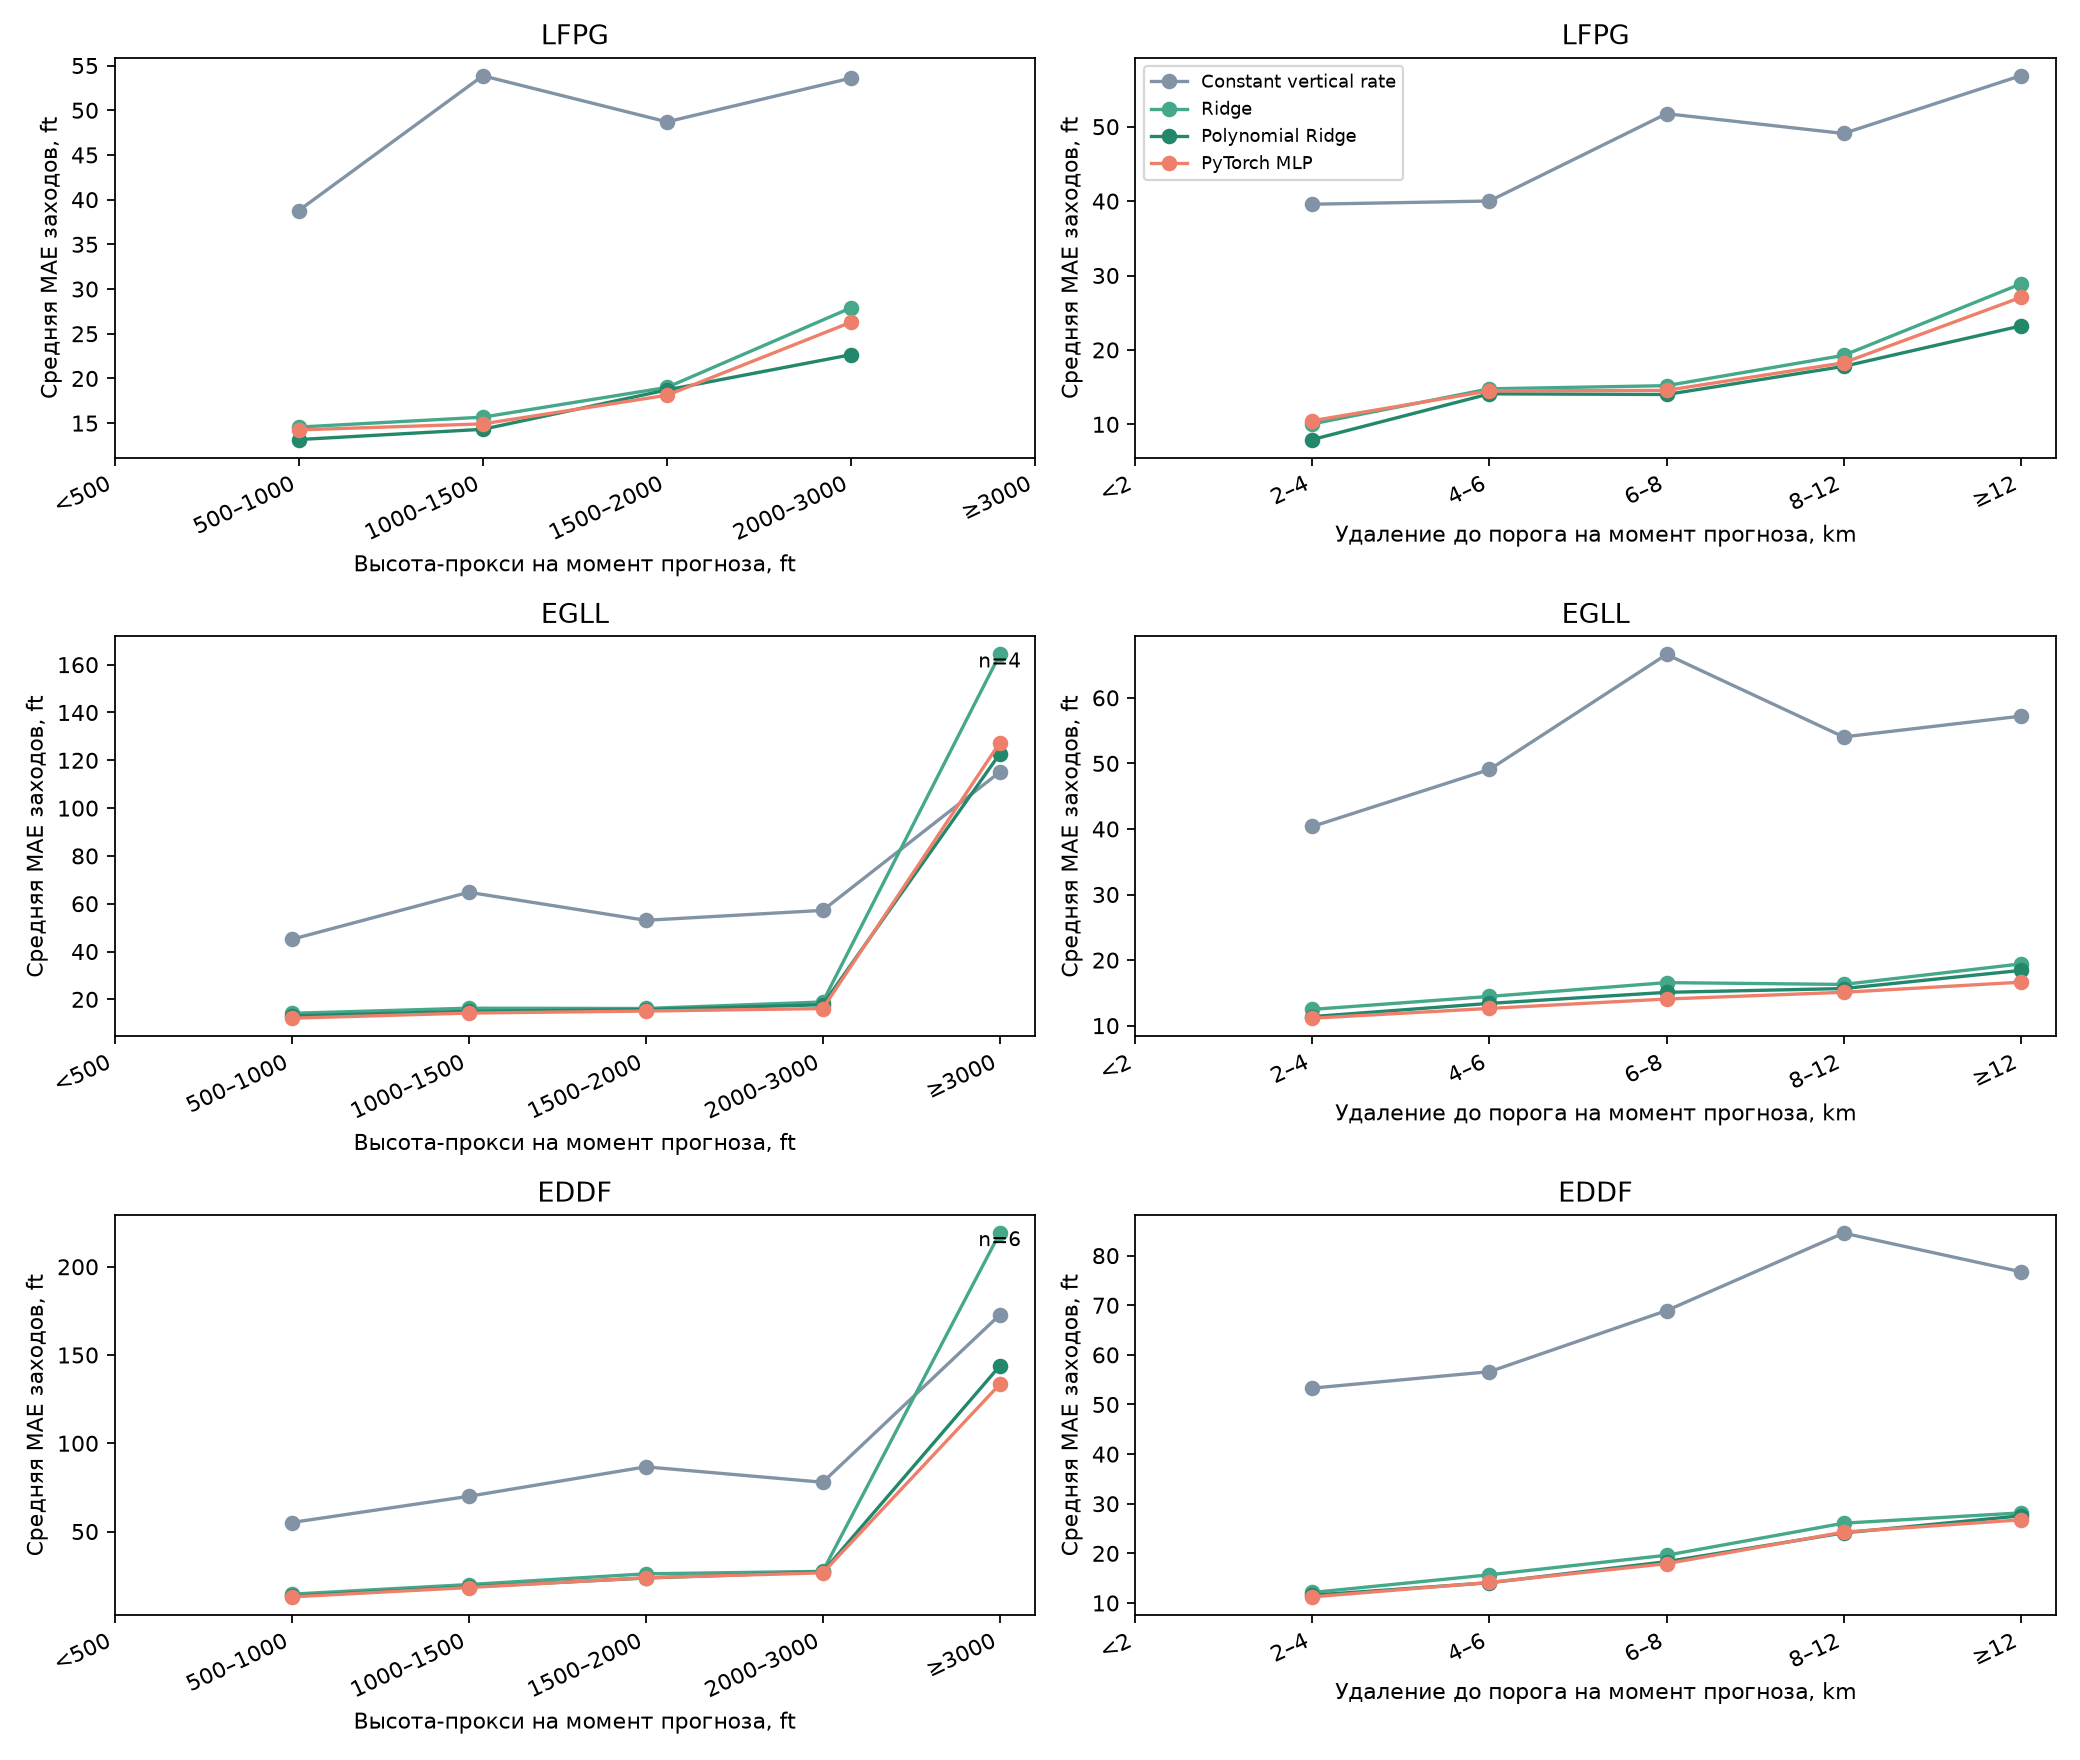

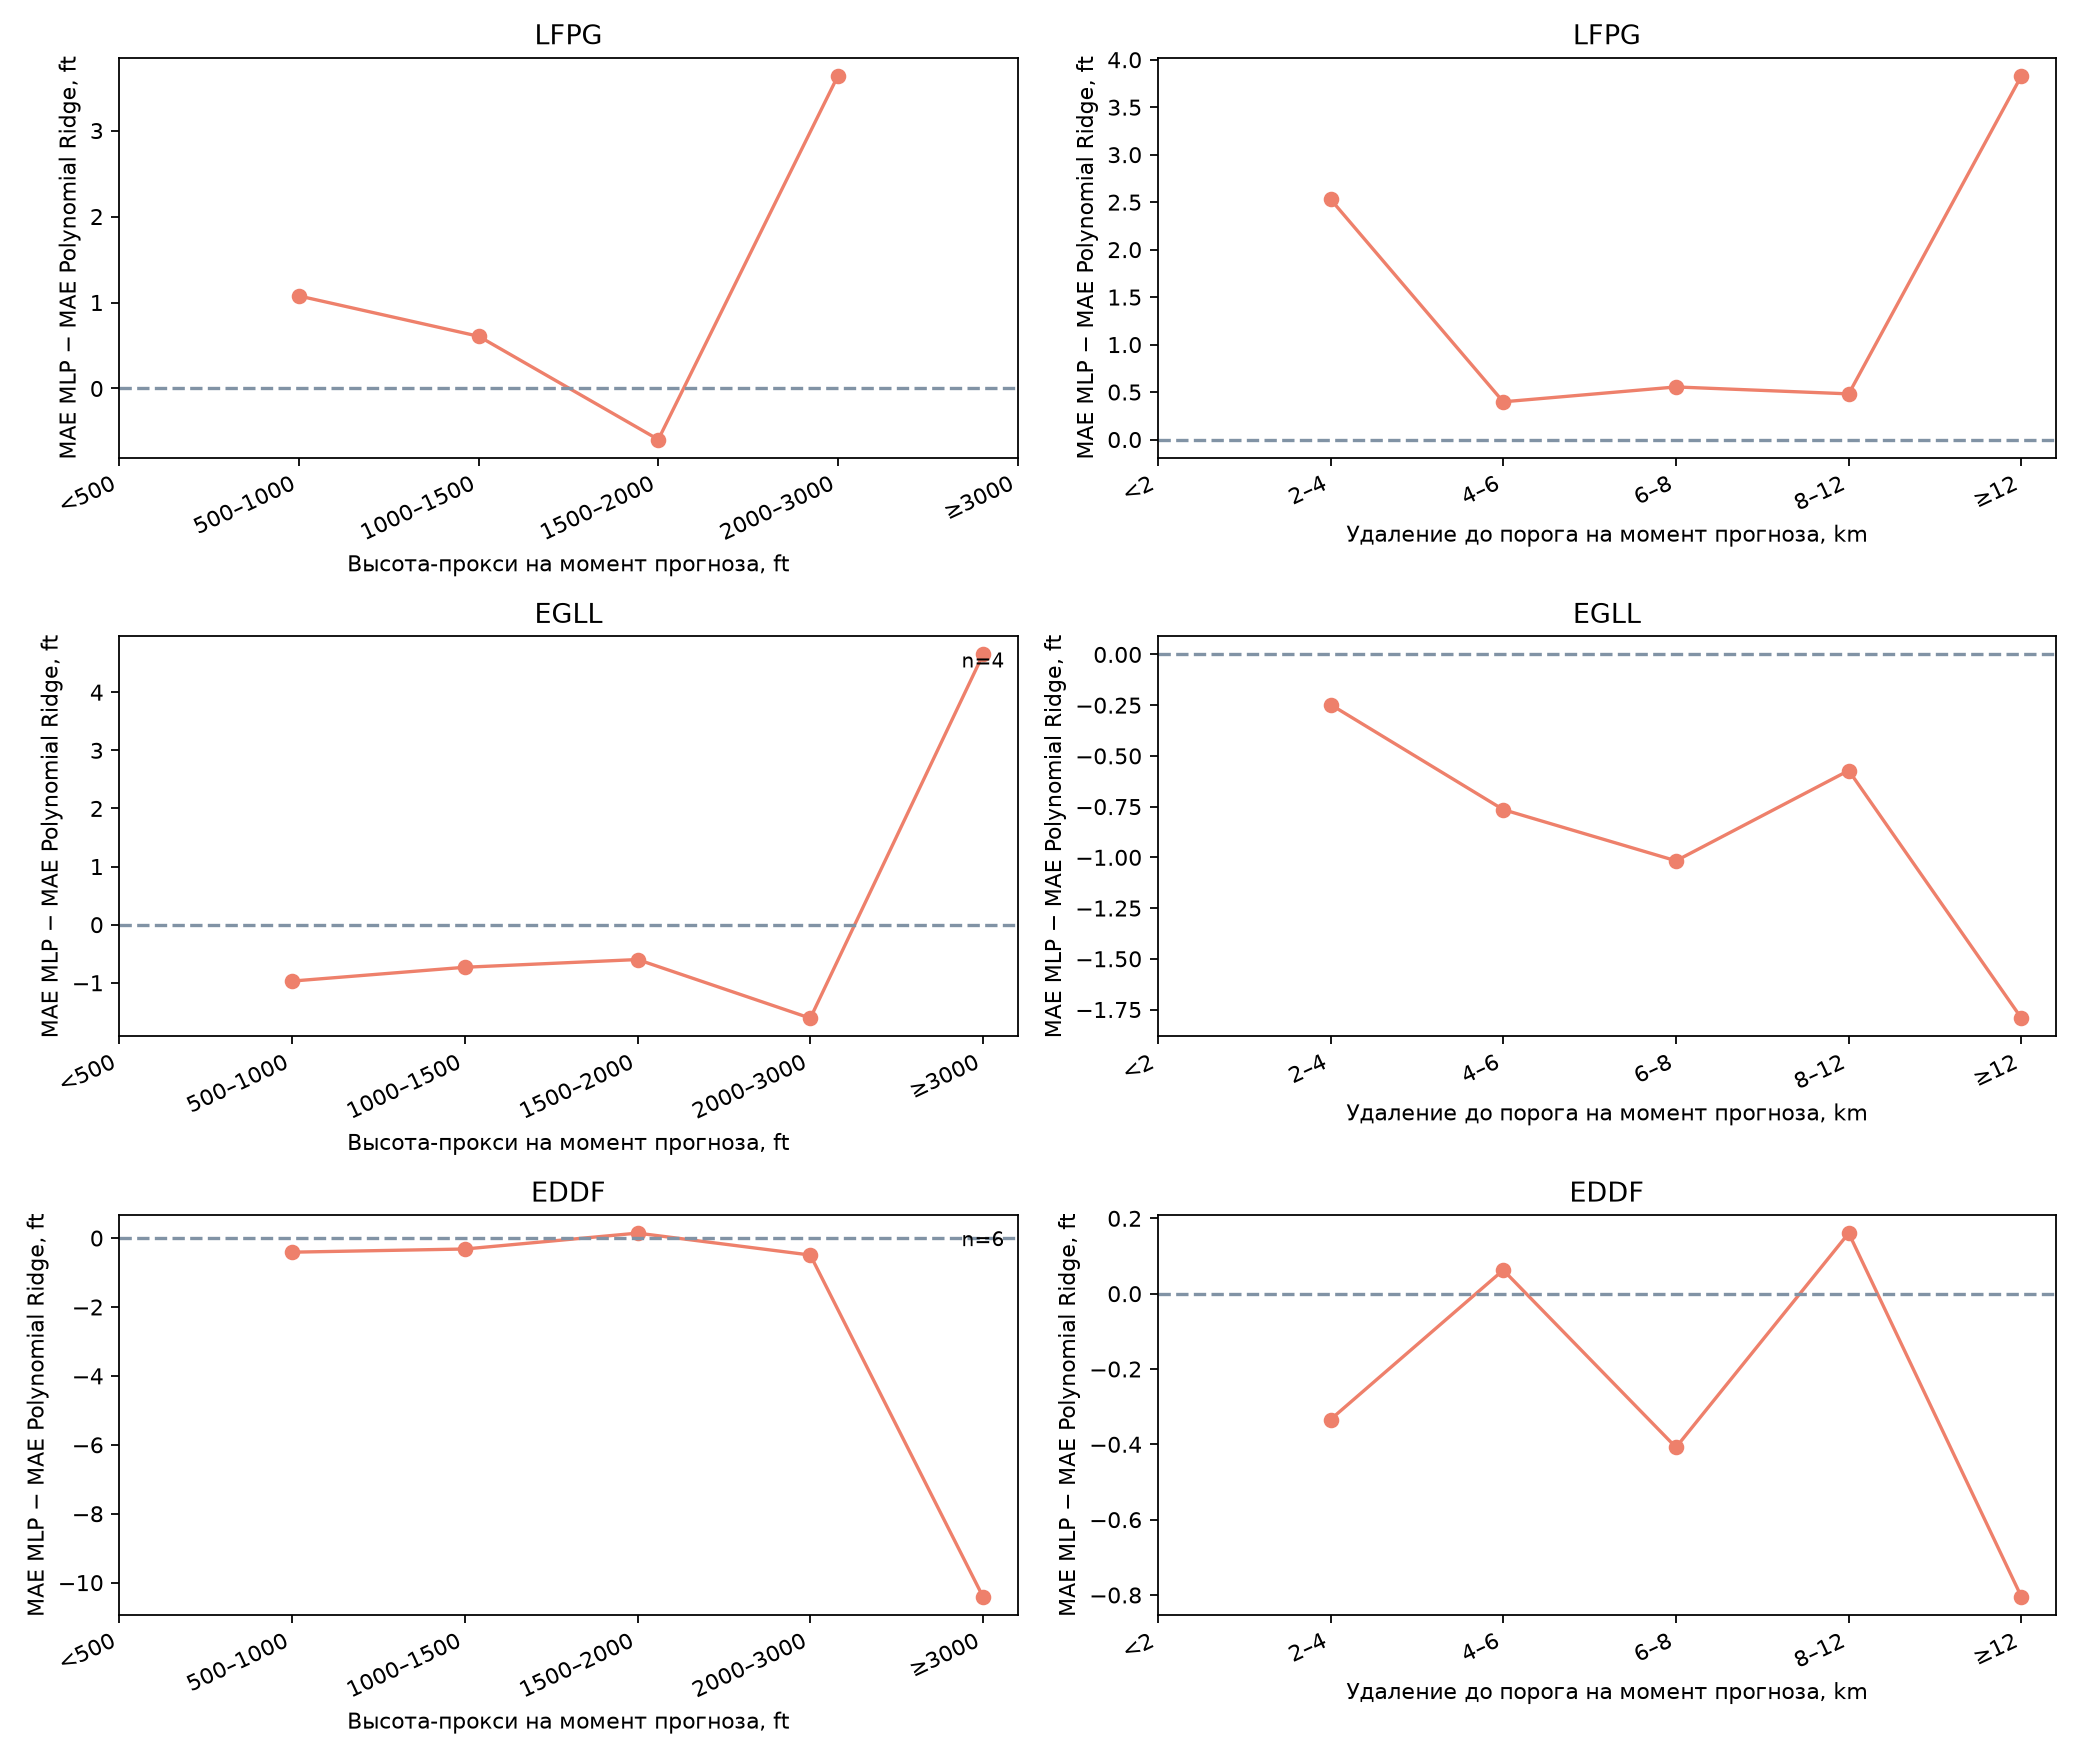

In [6]:
# Показываем ошибки, размеры групп и парные разницы фиксированных моделей
display(pd.read_csv(root / "reports/phase_errors.csv"))
display(pd.read_csv(root / "reports/phase_paired_errors.csv"))
display(Image(filename=str(root / "reports/phase_mae.png")))
display(Image(filename=str(root / "reports/phase_delta.png")))

В LFPG наибольший проигрыш MLP относительно Polynomial Ridge наблюдается в интервалах 2000–3000 ft и от 12 km. В EGLL средняя разница отрицательна во всех интервалах с большим числом заходов. В EDDF знак зависит от интервала. Группы от 3000 ft содержат лишь 4 захода EGLL и 6 EDDF; эти крайние значения не подтверждают устойчивую закономерность. Ниже 500 ft и ближе 2 km наблюдений нет. Интервалы неопределенности здесь не рассчитаны; анализ описательный, после просмотра test, без нового выбора параметров или признаков

## Распределение ошибок и вклад худших заходов

Медиана, P90 и P95 рассчитаны по MAE отдельных заходов с равным весом. Квантили используют линейную интерполяцию. Число худших заходов равно ceil(0.05 × N): 3 из 55 LFPG, 57 из 1136 EGLL, 27 из 540 EDDF. Поэтому фактическая доля может немного превышать 5%. Концентрация – доля суммы MAE заходов, не сумма ошибок всех прогнозных точек. Для каждой модели худшая группа определяется отдельно

В парной таблице дополнительно сравнивается один общий набор худших заходов, выбранный по MAE Polynomial Ridge. Это зависимая от модели сравнения группа, а не независимая проверка преимущества MLP. Ниже диагонали на графике MLP лучше

,airport,model,events,macro_mae_ft,median_event_mae_ft,p90_event_mae_ft,p95_event_mae_ft,worst_events,worst_fraction,worst_share_of_sum_event_mae
0,LFPG,Constant vertical rate,55,49.348959,51.519422,74.137550,75.951686,3,0.054545,0.117464
1,LFPG,Ridge,55,20.033286,18.875424,29.025180,35.940440,3,0.054545,0.107427
2,LFPG,Polynomial Ridge,55,17.163963,16.830567,23.851737,28.695757,3,0.054545,0.096758
3,LFPG,PyTorch MLP,55,18.862559,17.674079,28.466838,30.039663,3,0.054545,0.099383
4,EGLL,Constant vertical rate,1136,55.953272,51.184925,91.399243,106.090410,57,0.050176,0.119474
5,EGLL,Ridge,1136,16.337442,14.753677,23.114637,27.150999,57,0.050176,0.117278
6,EGLL,Polynomial Ridge,1136,15.448957,13.999911,22.493687,25.877160,57,0.050176,0.116727
7,EGLL,PyTorch MLP,1136,14.516123,13.111902,21.770759,25.765808,57,0.050176,0.113921
8,EDDF,Constant vertical rate,540,72.603506,65.900077,108.620630,137.518430,27,0.050000,0.143741
9,EDDF,Ridge,540,22.225478,19.399780,34.577528,42.305244,27,0.050000,0.128414


,airport,events,mean_delta_mae_ft,median_delta_mae_ft,better_events,worse_events,tied_events,reference_worst_events,reference_worst_poly_mae_ft,reference_worst_mlp_mae_ft,reference_worst_mean_delta_ft,remaining_mean_delta_ft
0,LFPG,55,1.698596,1.086284,13,42,0,3,30.447180,31.394521,0.947341,1.741937
1,EGLL,1136,-0.932835,-0.743879,777,359,0,57,35.939711,32.179919,-3.759792,-0.783496
2,EDDF,540,-0.310811,-0.244454,294,246,0,27,49.926590,46.856974,-3.069616,-0.165611


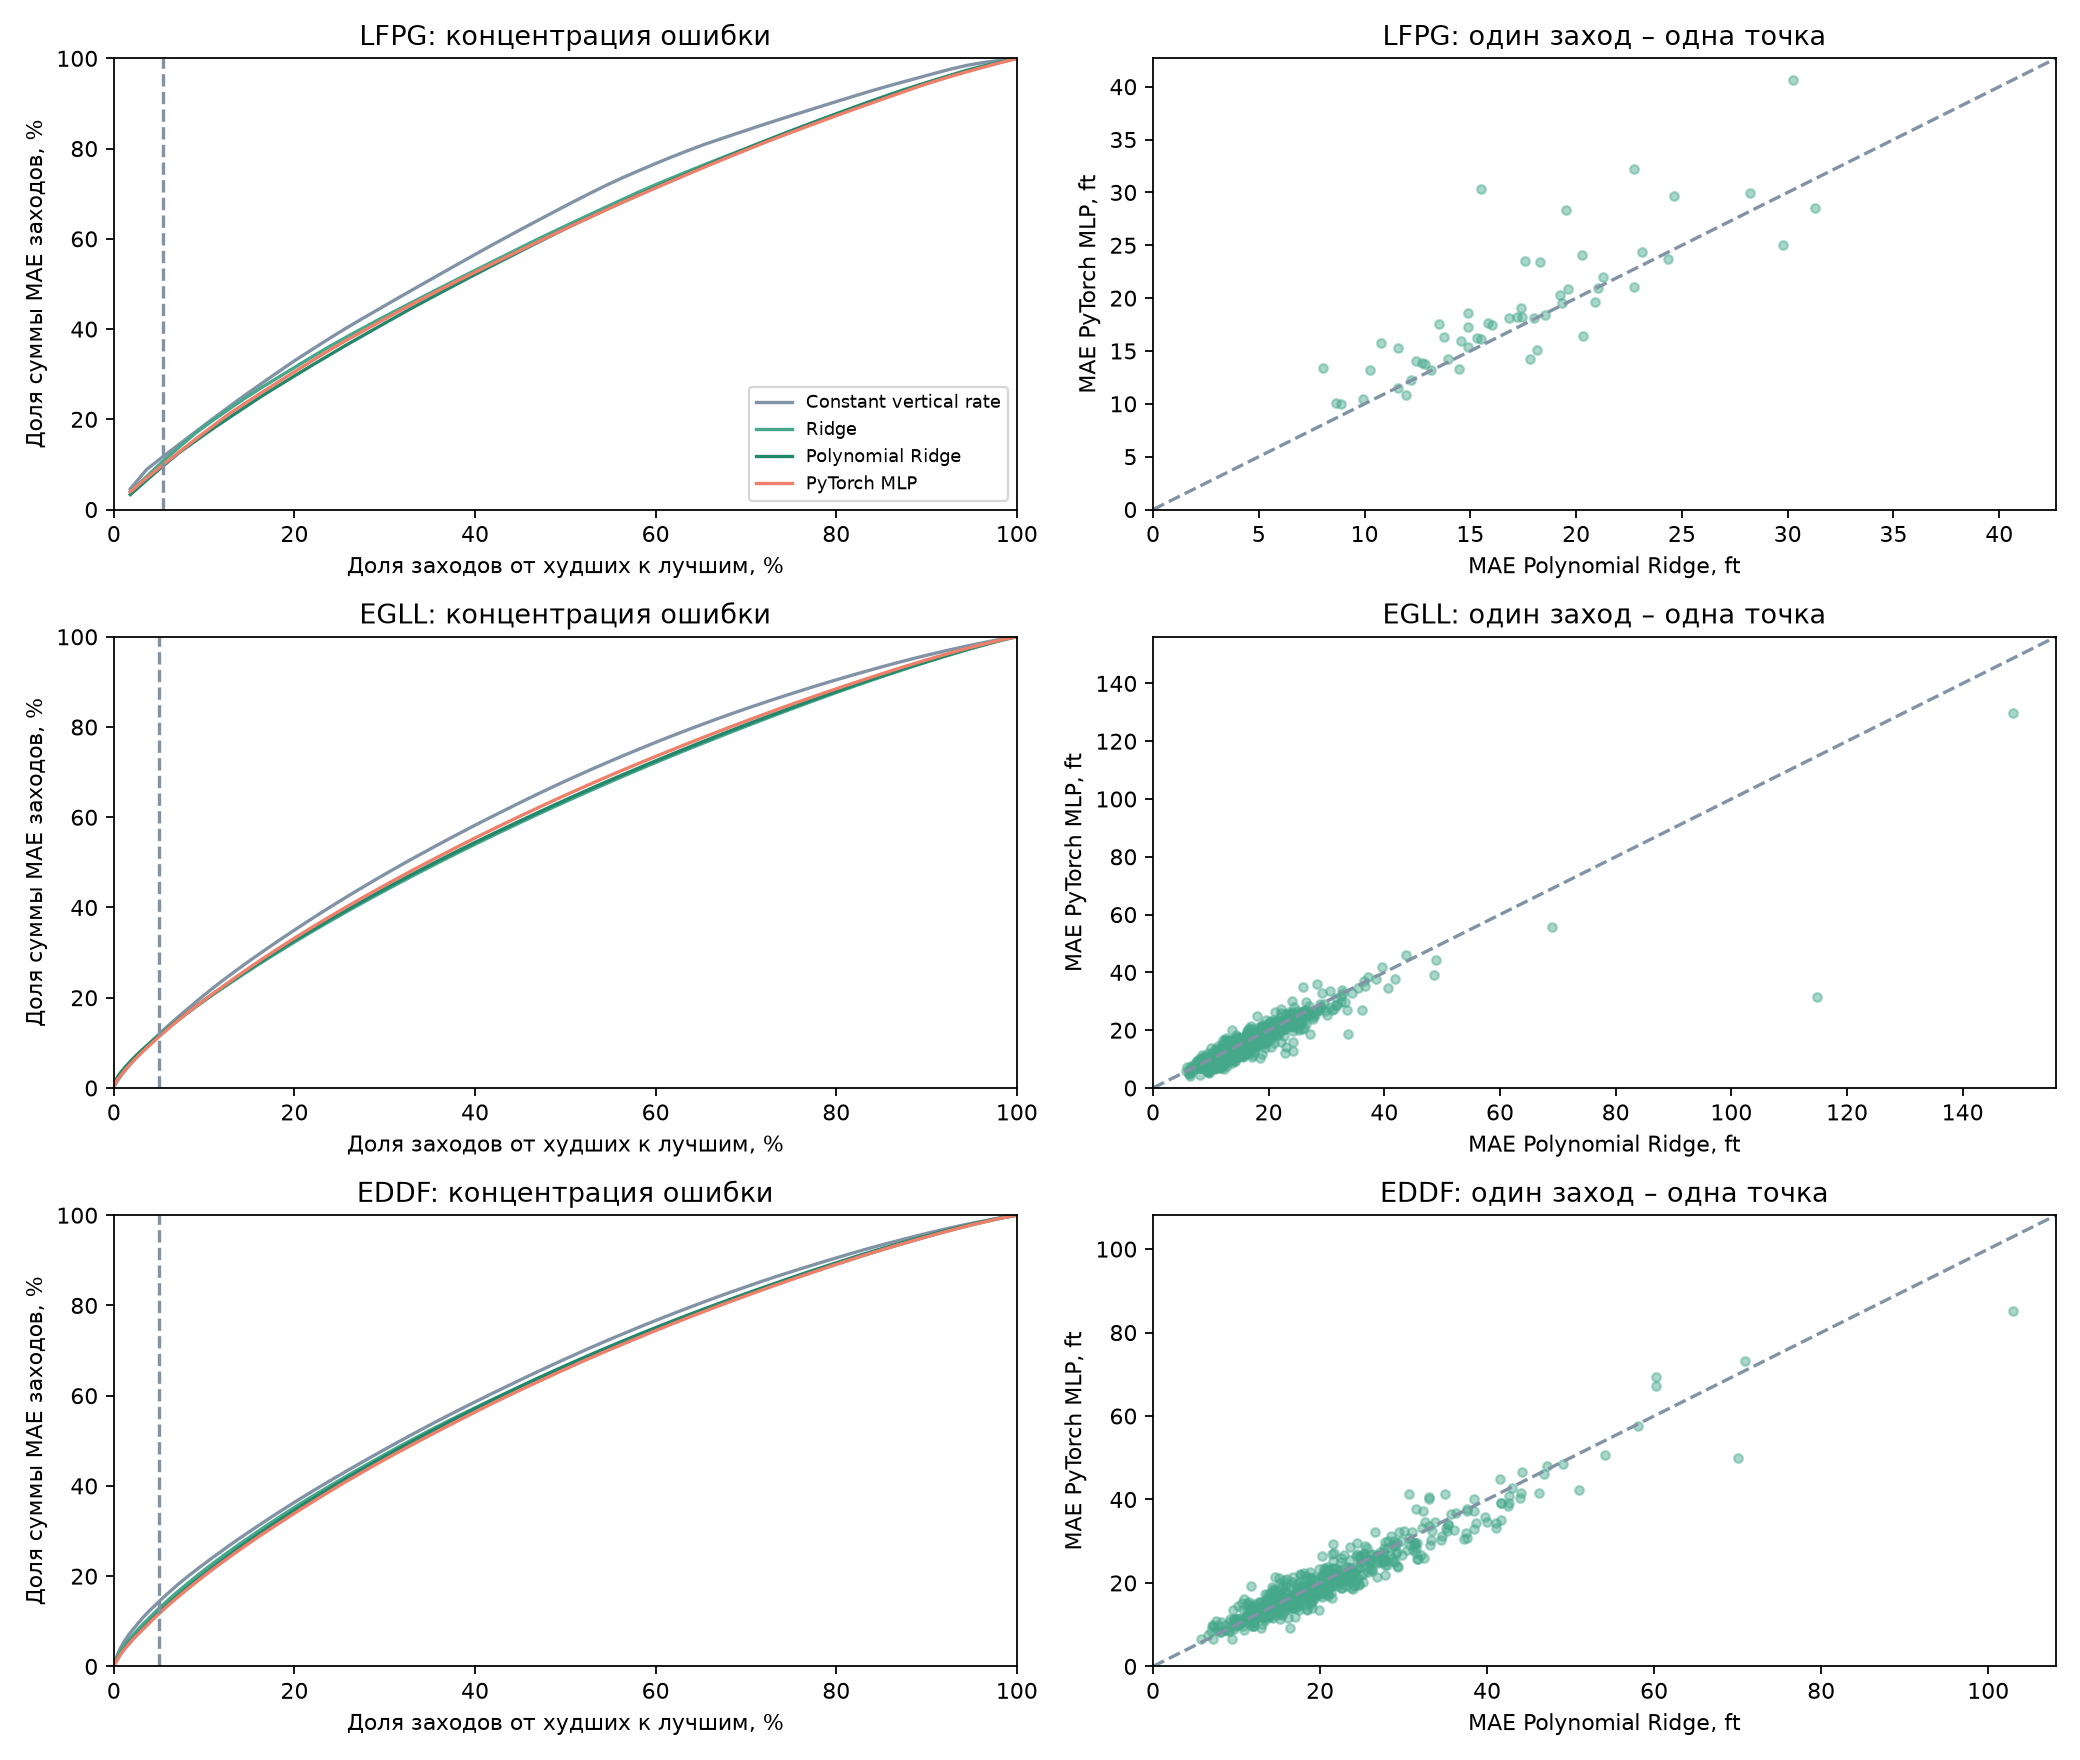

In [7]:
# Показываем квантили, концентрацию ошибки и парное сравнение заходов
display(pd.read_csv(root / "reports/error_tails.csv"))
display(pd.read_csv(root / "reports/error_tails_paired.csv"))
display(Image(filename=str(root / "reports/error_tails.png")))

В LFPG Polynomial Ridge лучше MLP по медиане, P90 и P95. В EGLL MLP уменьшает медиану с 14.00 до 13.11 ft и P90 с 22.49 до 21.77 ft; P95 меняется мало: 25.88 против 25.77 ft. В EDDF медианы практически совпадают (18.735 и 18.737 ft), P95 уменьшается с 38.76 до 37.85 ft. Квантили MAE моделей и медиана парных разниц отвечают на разные вопросы

Худшие группы обучаемых моделей дают около 10–12% суммы MAE, для Ridge EDDF около 13%. На общей группе худших заходов Polynomial Ridge MLP уменьшает среднюю MAE в EGLL на 3.76 ft и EDDF на 3.07 ft; на остальных заходах средние разницы также отрицательны: −0.78 и −0.17 ft. В LFPG обе разницы положительны. Наблюдаемая средняя разница не определяется только этой худшей группой. Анализ выполнен после просмотра test, без интервалов неопределенности. P95 LFPG основан на 55 заходах и особенно чувствителен к составу выборки. Хвост MAE заходов не описывает хвост мгновенных ошибок высоты

## Чувствительность выбранной MLP к seed

Для каждого аэропорта повторены пять запусков с seed 20261014–20261018. Архитектура зафиксирована по исходному выбору на validation: LFPG 9 → 16 → 16 → 1, EGLL и EDDF 9 → 32 → 32 → 1. Сохраняются исходные признаки, split, оптимизатор, веса заходов и правило ранней остановки. Меняются инициализация весов и порядок minibatch. Лучший epoch каждого запуска выбирается только по validation

Все 15 обучений завершены перед новой оценкой test. Все seed представлены в отчетах; лучший по test не выбирается, исходные модели не заменены, ансамбль не строится. Исходный seed воспроизводит исходную MAE каждого аэропорта. Разброс между seed не является доверительным интервалом и не учитывает неопределенность новых дней. Это дополнительная диагностика после просмотра исходного test

,airport,seed,width,validation_macro_mae_ft,best_epoch,stopped_epoch,run_id,artifact_sha256
0,LFPG,20261014,16,17.064349,145,175,a7c0aaac783649adb0da2913e6102f6e,ea15c4fbe25424e90a9d89a917fa7f3b4512dcc88ca27d...
1,LFPG,20261015,16,17.117098,138,168,3b5cfe8fc7784634871b60f2aea9533d,841988944d8d59ef1b32041ef7b23f2ca28f6989a7ea3a...
2,LFPG,20261016,16,17.001616,131,161,45b29f5394e9465da04ef8eaf182820d,cbc580efe2acb6e96fd27cca0ace4e6e3e87cb21db5c45...
3,LFPG,20261017,16,16.962863,153,183,928a362e5d5641f8a7f36c5cb1844cf4,2ad3ca84a5c7d8d7d496b6d933ade65dfc9567920d56df...
4,LFPG,20261018,16,17.154792,123,153,b439a205159b4a96969a1c583997af88,bf3cbc2af21196be1cc8aafbd796784aee83c53fd69b0a...
5,EGLL,20261014,32,14.886854,108,138,2a6dc9ea795646a3ac39b9208fda8090,40525f4332192909f60eb067f2d9947e2ebb39ff9a532e...
6,EGLL,20261015,32,14.908248,119,149,73f35a71a88045f2ae1f0de1bcc313b2,8b4e043dc56c3e4d9f3125bcac515ae991012929b05abe...
7,EGLL,20261016,32,15.124318,104,134,1f593d5607d54f7da7b2dfcfa950668c,c9d8d94e4d03d10ecd1e7e49011fdce3f24a866ceba040...
8,EGLL,20261017,32,15.148764,71,101,bf56b7159be546358aa296f17e15cd59,fcc5e70b02abb89970ecb2be617244d23d08ae51fee0ba...
9,EGLL,20261018,32,15.106402,70,100,26186ab7b59f44d9b7912ff6cc7ae526,8021815512cf62a90fdbb648a061c36a70d95908805267...


,airport,seed,macro_mae_ft,macro_rmse_ft,delta_vs_polynomial_ft
0,LFPG,20261014,18.862559,24.466738,1.698596
1,LFPG,20261015,20.772447,27.284171,3.608483
2,LFPG,20261016,19.243135,25.179120,2.079171
3,LFPG,20261017,19.425153,25.733344,2.261190
4,LFPG,20261018,18.950546,24.472225,1.786582
5,EGLL,20261014,14.516123,20.314007,-0.932835
6,EGLL,20261015,14.468515,20.609559,-0.980442
7,EGLL,20261016,14.727817,21.262574,-0.721140
8,EGLL,20261017,14.794137,21.157614,-0.654820
9,EGLL,20261018,14.488180,21.013655,-0.960777


,airport,seeds,mean_mae_ft,sd_mae_ft,min_mae_ft,max_mae_ft,mean_delta_ft,min_delta_ft,max_delta_ft,seeds_better_than_polynomial
0,EDDF,5,20.499129,0.095010,20.368645,20.616469,-0.374316,-0.504800,-0.256975,5
1,EGLL,5,14.598954,0.150705,14.468515,14.794137,-0.850003,-0.980442,-0.654820,5
2,LFPG,5,19.450768,0.772466,18.862559,20.772447,2.286804,1.698596,3.608483,0


,airport,seed,day,events,macro_mae_ft,polynomial_macro_mae_ft,delta_vs_polynomial_ft
0,LFPG,20261014,2025-03-17,24,20.467804,17.927073,2.540732
1,LFPG,20261014,2025-08-25,17,18.336479,16.781650,1.554829
2,LFPG,20261014,2025-11-04,14,16.749520,16.320013,0.429507
3,LFPG,20261015,2025-03-17,24,23.447561,17.927073,5.520488
4,LFPG,20261015,2025-08-25,17,20.144817,16.781650,3.363166
5,LFPG,20261015,2025-11-04,14,16.948659,16.320013,0.628645
6,LFPG,20261016,2025-03-17,24,21.967475,17.927073,4.040403
7,LFPG,20261016,2025-08-25,17,18.350773,16.781650,1.569122
8,LFPG,20261016,2025-11-04,14,15.656419,16.320013,-0.663595
9,LFPG,20261017,2025-03-17,24,21.461413,17.927073,3.534340


mean_delta_ft  min_delta_ft  max_delta_ft  seeds_better
airport day                                                                
EDDF    2025-05-09      -1.001908     -1.404547     -0.692826             5
        2025-08-18      -0.066846     -0.268318      0.357403             3
        2025-10-19       0.087742     -0.195798      0.369763             3
EGLL    2025-04-07      -1.496155     -1.704336     -1.207823             5
        2025-08-25      -0.398798     -0.433107     -0.322613             5
        2025-10-18      -0.644264     -0.889803     -0.422290             5
LFPG    2025-03-17       3.672847      2.540732      5.520488             0
        2025-08-25       2.238267      1.554829      3.363166             0
        2025-11-04      -0.030330     -0.663595      0.628645             3

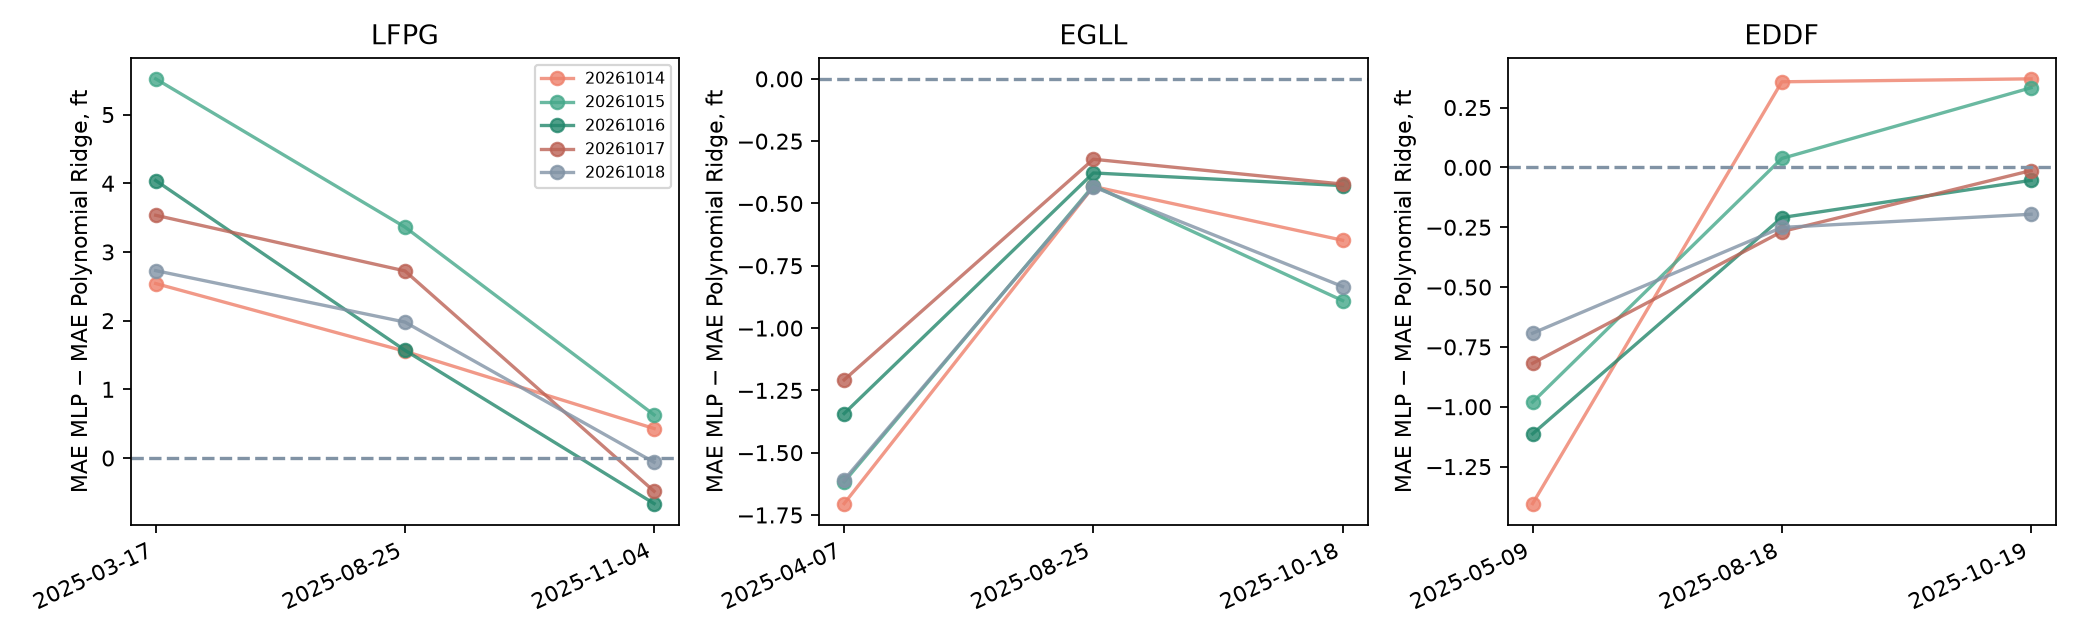

In [8]:
# Показываем все запуски, разброс и разницы по тестовым дням
display(pd.read_csv(root / "reports/seed_stability_runs.csv"))
display(pd.read_csv(root / "reports/seed_stability_metrics.csv"))
display(pd.read_csv(root / "reports/seed_stability_summary.csv"))
seed_days = pd.read_csv(root / "reports/seed_stability_by_day.csv")
display(seed_days)
# Сопоставляем диапазоны пяти seed внутри каждого фиксированного дня
display(seed_days.groupby(["airport", "day"]).agg(
    mean_delta_ft=("delta_vs_polynomial_ft", "mean"),
    min_delta_ft=("delta_vs_polynomial_ft", "min"),
    max_delta_ft=("delta_vs_polynomial_ft", "max"),
    seeds_better=("delta_vs_polynomial_ft", lambda values: int((values < 0).sum()))))
display(Image(filename=str(root / "reports/seed_stability.png")))

Все пять seed сохраняют знак общей разницы: в LFPG MLP хуже Polynomial Ridge на 1.70–3.61 ft, в EGLL лучше на 0.65–0.98 ft, в EDDF лучше на 0.26–0.50 ft. Средняя MAE MLP между seed составляет 19.45 ± 0.77 ft LFPG, 14.60 ± 0.15 ft EGLL и 20.50 ± 0.10 ft EDDF; после знака ± указано выборочное стандартное отклонение пяти запусков

В EGLL разница отрицательна на каждом из трех дней при каждом seed. В EDDF майская разница отрицательна для всех seed, а в августе и октябре знак зависит от seed. В LFPG весенняя и летняя разницы положительны при всех seed, осенняя меняет знак. Устойчивость общего среднего не означает устойчивость каждого дня или перенос на новые дни

## Ограничения сравнения

Размер и состав выборок различаются; абсолютная MAE не определяет сложность аэропорта. На сезон приходится один тестовый день, борта могут повторяться между split, фактический горизонт известен ретроспективно. Основные результаты относятся к исходному seed; дополнительная проверка пяти seed сохраняет те же дни и архитектуры. Парные интервалы оценены отдельно для каждого аэропорта и условны на наблюдаемых днях. Новые параметры по test не подбирались. Эксплуатационная применимость не установлена

## Совокупные исследовательские выводы

Обучаемая поправка уменьшает среднюю ошибку относительно продолжения вертикальной скорости во всех трех исследованных аэропортах. Универсального преимущества MLP над Polynomial Ridge не установлено: LFPG поддерживает Polynomial Ridge, EGLL поддерживает MLP на трех наблюдаемых днях, EDDF показывает смену знака разницы по дням. Эти выводы относятся к выбранным погожим дням и полосам

Следующая научная проверка должна заранее определить доступный на момент прогноза горизонт и независимые дни оценки. Текущие test-результаты не используются для нового подбора признаков или параметров. Go-around и эксплуатационная безопасность не оцениваются в этой работе

In [9]:
# Показываем проверку соответствия отчетов исходным MLflow runs
display(pd.read_csv(root / "reports/tracking_review.csv"))

,airport,model,run_id,metrics_match,git_commit_exists,dataset_hash_matches,artifact_root_entries
0,LFPG,Constant vertical rate,af81171321ba41da902589bff85a3858,True,True,True,3
1,LFPG,Ridge,58f9e5e9015e4478b4c9631b4aa613d0,True,True,True,4
2,LFPG,Polynomial Ridge,54224c6909c1451aa7c24c45feaa2dc5,True,True,True,4
3,LFPG,PyTorch MLP,e1e47564e32845768281b8f447e7e21b,True,True,True,5
4,EGLL,Constant vertical rate,77511f5022e34b5caf1c988466047793,True,True,True,3
5,EGLL,Ridge,019df70260ad45ec9299b2efc60829cc,True,True,True,4
6,EGLL,Polynomial Ridge,a1836409248444b0ae6250bd2a1aa52c,True,True,True,4
7,EGLL,PyTorch MLP,7432f453bb1e46e0924dc4ae5bfb212a,True,True,True,5
8,EDDF,Constant vertical rate,ab3f157c9a354866bb3673c2dd4f4138,True,True,True,3
9,EDDF,Ridge,586f82fc484d45c69e23761575b0b58b,True,True,True,4
